# 04 · Model Evaluation and Error Analysis

**Goal:** understand where each model fails, not only how accurate it is, and choose the model for the dashboard.

## Steps
1. Load the predictions from notebook 03
2. Confusion matrix per model
3. Per-class F1 scores
4. Error analysis of the best model
5. Model agreement
6. Majority-vote ensemble
7. Final choice

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix, classification_report, 
    precision_recall_fscore_support, accuracy_score
)

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 5)
pd.set_option('display.max_colwidth', 150)


In [2]:
# Predictions from notebook 03
preds = pd.read_csv('../data/processed/model_predictions.csv')
results = pd.read_csv('../data/processed/model_results.csv')

print(f"Predictions shape: {preds.shape}")
print(f"\nColumns: {list(preds.columns)}")
preds.head(3)

Predictions shape: (2893, 7)

Columns: ['text_clean', 'text_tokens', 'true_label', 'vader_pred', 'nb_pred', 'lr_pred', 'hf_pred']


,text_clean,text_tokens,true_label,vader_pred,nb_pred,lr_pred,hf_pred
0,so no idea thanks,no idea thanks,neutral,negative,negative,neutral,negative
1,does anyone realize that banning peanuts on a flight due to an allergic person ignores p nut oil and dust from previous flights,anyone realize banning peanuts flight due allergic person ignores nut oil dust previous flights,negative,negative,negative,negative,negative
2,this was the rd cancellation in days due to weather in nashville trips to the airport each time communicated late by sw,rd cancellation days due weather nashville trips airport time communicated late sw,negative,neutral,negative,negative,negative


In [3]:
# Accuracy leaderboard from notebook 03
results

,Model,Type,Accuracy,Time (s),Accuracy %
0,Logistic Regression,Classical ML,0.777394,0.365891,77.74
1,Naive Bayes,Classical ML,0.746630,0.019359,74.66
2,DistilBERT,Deep Learning,0.709298,53.494542,70.93
3,VADER,Rule-based,0.554442,0.128632,55.44


---

## 2. Confusion matrices

Each row is the actual sentiment and each column the predicted one, as a percentage of the actual class. The diagonal shows correct predictions; dark cells off the diagonal show systematic errors.

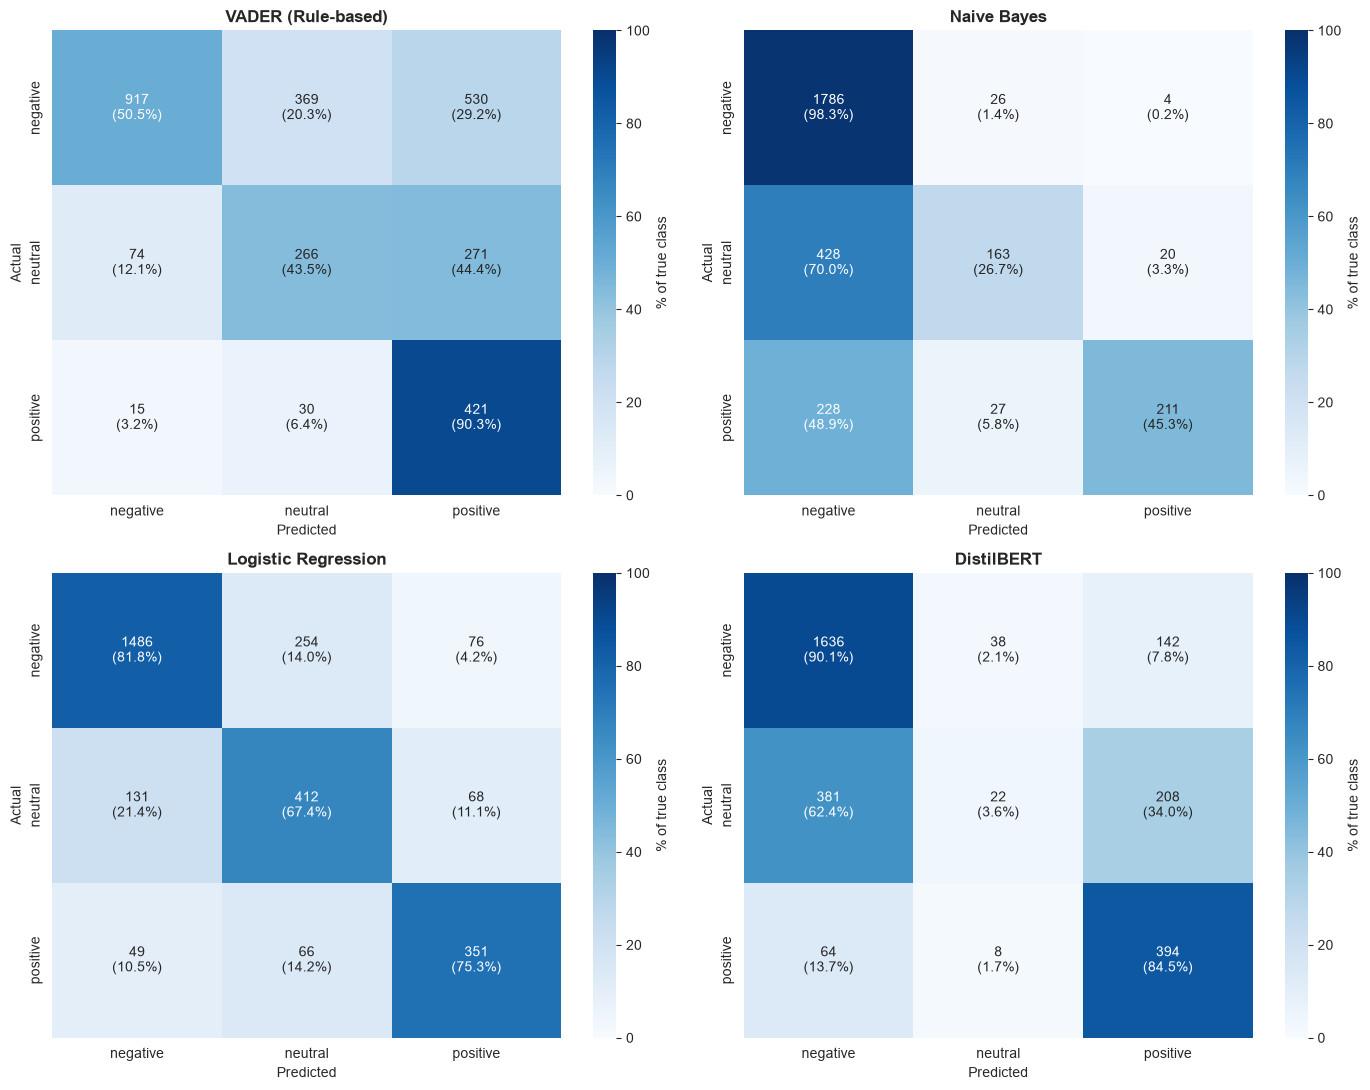

In [4]:
# Confusion matrix as row percentages
def plot_cm(y_true, y_pred, title, ax):
    labels = ['negative', 'neutral', 'positive']
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100  # convert to %
    
    # Each cell shows the count and the % of the actual class
    annot = np.array([
        [f"{count}\n({pct:.1f}%)" for count, pct in zip(row_c, row_p)]
        for row_c, row_p in zip(cm, cm_pct)
    ])
    
    sns.heatmap(cm_pct, annot=annot, fmt='', cmap='Blues',
                xticklabels=labels, yticklabels=labels, ax=ax,
                cbar_kws={'label': '% of true class'}, vmin=0, vmax=100)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.set_title(title, fontsize=12, fontweight='bold')

# One confusion matrix per model
fig, axes = plt.subplots(2, 2, figsize=(14, 11))

models_info = [
    ('vader_pred', 'VADER (Rule-based)', axes[0, 0]),
    ('nb_pred', 'Naive Bayes', axes[0, 1]),
    ('lr_pred', 'Logistic Regression', axes[1, 0]),
    ('hf_pred', 'DistilBERT', axes[1, 1]),
]

for col, title, ax in models_info:
    plot_cm(preds['true_label'], preds[col], title, ax)

plt.tight_layout()
plt.savefig('../data/processed/confusion_matrices.png', dpi=100, bbox_inches='tight')
plt.show()

### What the confusion matrices show

- **VADER** labels many negative tweets as positive or neutral: it catches only half of the negative tweets (recall 0.50).
- **Naive Bayes** leans heavily toward the majority class: it finds 98% of negative tweets but only 27% of neutral ones.
- **DistilBERT** almost never predicts neutral (neutral recall 0.04), because it was trained for positive vs negative only.
- **Logistic Regression** is the most balanced across the three classes, helped by `class_weight='balanced'`.

---

## 3. Per-class F1 scores

With imbalanced classes, overall accuracy can hide weak classes. The F1 score per class shows how each model handles negative, neutral and positive tweets separately.

In [5]:
# Per-class F1 for each model
def get_per_class_f1(y_true, y_pred):
    labels = ['negative', 'neutral', 'positive']
    _, _, f1, _ = precision_recall_fscore_support(y_true, y_pred, labels=labels, zero_division=0)
    return dict(zip(labels, f1))

f1_data = []
for col, name in [('vader_pred', 'VADER'), ('nb_pred', 'Naive Bayes'), 
                   ('lr_pred', 'Logistic Regression'), ('hf_pred', 'DistilBERT')]:
    f1 = get_per_class_f1(preds['true_label'], preds[col])
    f1_data.append({'Model': name, **f1})

f1_df = pd.DataFrame(f1_data).set_index('Model')
print("F1-score per class:")
print(f1_df.round(3))

F1-score per class:
                     negative  neutral  positive
Model                                           
VADER                   0.650    0.417     0.499
Naive Bayes             0.839    0.394     0.602
Logistic Regression     0.854    0.614     0.730
DistilBERT              0.840    0.065     0.651


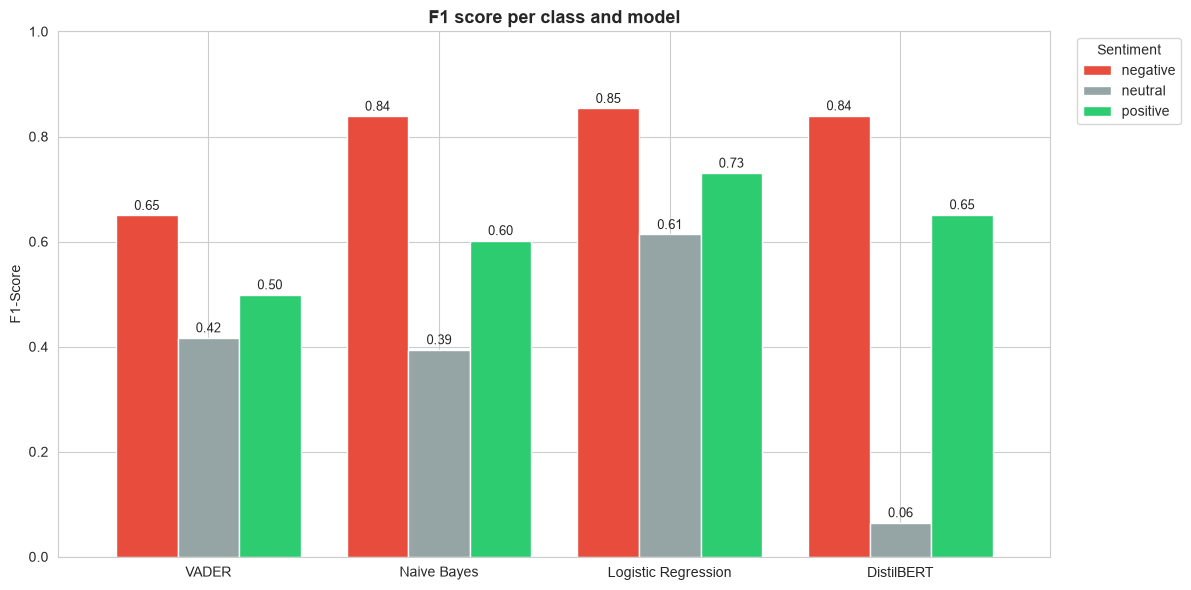

In [6]:
# Visualize as grouped bar chart
fig, ax = plt.subplots(figsize=(12, 6))
f1_df.plot(kind='bar', ax=ax, color=['#e74c3c', '#95a5a6', '#2ecc71'], width=0.8)

ax.set_title('F1 score per class and model', fontsize=13, fontweight='bold')
ax.set_ylabel('F1-Score')
ax.set_xlabel('')
ax.set_ylim(0, 1)
ax.legend(title='Sentiment', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.tick_params(axis='x', rotation=0)

# Annotate bar values
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=2, fontsize=9)

plt.tight_layout()
plt.savefig('../data/processed/f1_per_class.png', dpi=100, bbox_inches='tight')
plt.show()

### Findings

- **Neutral is the hardest class for every model.** Neutral tweets often look like polite complaints or polite questions, and even annotators disagree on them.
- **Negative is the easiest class** (F1 0.84–0.85 for the three learned models): it is the largest class and uses distinctive words such as *worst*, *delayed* and *cancelled*.
- **Logistic Regression has the best F1 on all three classes**: negative 0.85, neutral 0.61 and positive 0.73.

---

## 4. Error analysis

The most common mistakes of **Logistic Regression**, the best model, with example tweets.

In [7]:
# Flag correct Logistic Regression predictions
preds['lr_correct'] = preds['true_label'] == preds['lr_pred']

# Error breakdown
error_breakdown = preds[~preds['lr_correct']].groupby(
    ['true_label', 'lr_pred']
).size().reset_index(name='count').sort_values('count', ascending=False)

print("Top error patterns (LR model):")
print(error_breakdown.head(10).to_string(index=False))

Top error patterns (LR model):
true_label  lr_pred  count
  negative  neutral    254
   neutral negative    131
  negative positive     76
   neutral positive     68
  positive  neutral     66
  positive negative     49


In [8]:
# Example tweets for one error pattern
def show_error_examples(true_label, pred_label, n=5):
    errors = preds[
        (preds['true_label'] == true_label) & 
        (preds['lr_pred'] == pred_label)
    ]
    print(f"Actual {true_label}, predicted {pred_label} ({len(errors)} tweets)")
    print("=" * 100)
    for idx, row in errors.head(n).iterrows():
        print(f"  • {row['text_clean']}")
    print()

# The three largest error patterns
print("Logistic Regression errors, largest patterns first:\n")
top_errors = error_breakdown.head(3)
for _, row in top_errors.iterrows():
    show_error_examples(row['true_label'], row['lr_pred'], n=5)

Logistic Regression errors, largest patterns first:

Actual negative, predicted neutral (254 tweets)
  • yeah buy me a plane ticket from san diego to detroit so i can fly one of their planes home tomorrow
  • promotion e mail today vegas and jamaica has a defective link for the vegas sweepstakes it times out with error
  • hello i never received a confirmation code for my flights though they are confirmed so says the automated reply any ideas
  • ratchet airway
  • sfo to bos and no internet it is what gives

Actual neutral, predicted negative (131 tweets)
  • considering it was past midnight i hung up and called again to receive another service call
  • i need the phone number to baggage claim in lax my mom left her phone and someone called saying they would put it there but on
  • quick question i bought wifi for my phone do i have to buy it again on my tablet i have hours left on my trip
  • how do i find travel funds i have available to use f past changed flights do not see an opti

### Why the model gets these wrong

The examples above show four recurring causes:
1. **Positive words in a complaint:** *"i just wish that a team member would pick up the phone … let alone be courteous or helpful"* is negative, but *courteous* and *helpful* pull it toward positive.
2. **Complaints phrased as questions:** *"hello i never received a confirmation code for my flights … any ideas"* is labeled negative but reads like a neutral request.
3. **Ambiguous labels:** *"considering it was past midnight i hung up and called again"* is labeled neutral but reads like a complaint, so the annotators themselves may disagree.
4. **Very short tweets and slang:** *"ratchet airway"* gives the model almost nothing to work with.

For a social care team, the costliest error is a **negative tweet predicted as neutral** (the largest pattern, 254 tweets), because a complaint could be missed. Routing low-confidence predictions to a person reduces that risk (see section 5).

### Tweets that every model got wrong

When all four models are wrong, the tweet is either very hard (sarcasm, missing context) or its label is debatable.

In [9]:
# Tweets that all four models got wrong
all_wrong = preds[
    (preds['vader_pred'] != preds['true_label']) &
    (preds['nb_pred'] != preds['true_label']) &
    (preds['lr_pred'] != preds['true_label']) &
    (preds['hf_pred'] != preds['true_label'])
]

print(f"Tweets that every model got wrong: {len(all_wrong)} ({len(all_wrong)/len(preds)*100:.1f}%)")
print("\n10 examples:")
print("=" * 100)
for idx, row in all_wrong.head(10).iterrows():
    print(f"Tweet: {row['text_clean']}")
    print(f"   True: {row['true_label']} | VADER: {row['vader_pred']} | NB: {row['nb_pred']} | LR: {row['lr_pred']} | HF: {row['hf_pred']}")
    print()

Tweets that every model got wrong: 148 (5.1%)

10 examples:
Tweet: lol great answer our agents are checking in passengers as quickly as possible we appreciate your patience
   True: neutral | VADER: positive | NB: negative | LR: positive | HF: positive

Tweet: yes it was sunday
   True: neutral | VADER: positive | NB: negative | LR: positive | HF: positive

Tweet: more or less after a night in a party hotel no sleep and a am rebook on our way back to phl
   True: neutral | VADER: positive | NB: negative | LR: negative | HF: negative

Tweet: of course you are because that s your companies job you guys failed at it in the first place upgrade me and then we ll talk
   True: neutral | VADER: negative | NB: negative | LR: positive | HF: negative

Tweet: i understand why the pilot would get on the plane but why st class there were empty coach seats near me i m a premier k
   True: neutral | VADER: negative | NB: negative | LR: negative | HF: negative

Tweet: could really use your help gettin

---

## 5. Model agreement

When the four models agree, the prediction is more likely to be right. Agreement can therefore serve as a **confidence signal** for deciding which tweets need a human review.

In [10]:
# How many models agree on each tweet
def count_agreement(row):
    preds_list = [row['vader_pred'], row['nb_pred'], row['lr_pred'], row['hf_pred']]
    return max(preds_list.count(p) for p in set(preds_list))

preds['agreement'] = preds.apply(count_agreement, axis=1)

# Agreement distribution
agreement_dist = preds['agreement'].value_counts().sort_index()
print("Number of models that agree on a tweet:")
print(agreement_dist)
print("\nAs % of tweets:")
print((agreement_dist / len(preds) * 100).round(1))

Number of models that agree on a tweet:
agreement
2     745
3    1098
4    1050
Name: count, dtype: int64

As % of tweets:
agreement
2    25.8
3    38.0
4    36.3
Name: count, dtype: float64


In [11]:
# Logistic Regression accuracy by agreement level
print("Logistic Regression accuracy by agreement level:")

for agree in sorted(preds['agreement'].unique()):
    subset = preds[preds['agreement'] == agree]
    pred_col = 'lr_pred'  # accuracy of the chosen model
    acc = (subset[pred_col] == subset['true_label']).mean()
    print(f"  {agree} models agree: accuracy {acc:.3f} ({len(subset)} tweets, {len(subset)/len(preds)*100:.1f}%)")

Logistic Regression accuracy by agreement level:
  2 models agree: accuracy 0.558 (745 tweets, 25.8%)
  3 models agree: accuracy 0.761 (1098 tweets, 38.0%)
  4 models agree: accuracy 0.950 (1050 tweets, 36.3%)


### Findings

- When **all four models agree** (36% of tweets), Logistic Regression is right **95%** of the time.
- When **only two agree** (26% of tweets), its accuracy drops to **56%**.

**Use case:** a social care tool could act automatically on high-agreement tweets and send low-agreement tweets to a person for review.

---

## 6. Majority-vote ensemble

What happens if the four models vote?

In [12]:
from collections import Counter

def majority_vote(row):
    votes = [row['vader_pred'], row['nb_pred'], row['lr_pred'], row['hf_pred']]
    return Counter(votes).most_common(1)[0][0]

preds['ensemble_pred'] = preds.apply(majority_vote, axis=1)
ensemble_acc = (preds['ensemble_pred'] == preds['true_label']).mean()

# All models plus the ensemble
print("Accuracy including the ensemble:")
final_results = pd.DataFrame({
    'Model': ['VADER', 'Naive Bayes', 'Logistic Regression', 'DistilBERT', 'Ensemble (majority vote)'],
    'Accuracy': [
        (preds['vader_pred'] == preds['true_label']).mean(),
        (preds['nb_pred'] == preds['true_label']).mean(),
        (preds['lr_pred'] == preds['true_label']).mean(),
        (preds['hf_pred'] == preds['true_label']).mean(),
        ensemble_acc,
    ]
}).sort_values('Accuracy', ascending=False).reset_index(drop=True)
final_results['Accuracy %'] = (final_results['Accuracy'] * 100).round(2)
print(final_results[['Model', 'Accuracy %']].to_string(index=False))

Accuracy including the ensemble:
                   Model  Accuracy %
     Logistic Regression       77.74
Ensemble (majority vote)       77.43
             Naive Bayes       74.66
              DistilBERT       70.93
                   VADER       55.44


### Findings

- The ensemble (77.4%) is **slightly less accurate than Logistic Regression alone** (77.7%): the weaker models (VADER, DistilBERT) pull the vote down.
- It also needs all four models, including the slow DistilBERT, so it costs far more to run.

**Logistic Regression alone is the better choice.**

---

## 7. Final choice

Summary of the trade-offs:

In [13]:
# Summary of the trade-offs, computed from the notebook 03 results
r = results.set_index("Model")
summary = pd.DataFrame({
    "Accuracy": (r["Accuracy"] * 100).round(1).astype(str) + "%",
    "Time (s)": r["Time (s)"].round(2),
    "Interpretability": {"VADER": "High (rules)", "Naive Bayes": "Medium (probabilities)",
                         "Logistic Regression": "High (coefficients)", "DistilBERT": "Low (black box)"},
    "Deployment": {"VADER": "Easy, no training", "Naive Bayes": "Easy", "Logistic Regression": "Easy",
                   "DistilBERT": "Heavy (deep learning libraries, slow on CPU)"},
}).loc[["Logistic Regression", "Naive Bayes", "DistilBERT", "VADER"]]
summary

,Accuracy,Time (s),Interpretability,Deployment
Logistic Regression,77.7%,0.37,High (coefficients),Easy
Naive Bayes,74.7%,0.02,Medium (probabilities),Easy
DistilBERT,70.9%,53.49,Low (black box),"Heavy (deep learning libraries, slow on CPU)"
VADER,55.4%,0.13,High (rules),"Easy, no training"


### Chosen model: Logistic Regression

1. **Highest accuracy** (77.7%), 7 points above DistilBERT and above the four-model ensemble.
2. **Fast:** trains in under a second, while DistilBERT needs about a minute just to predict the test set on a CPU.
3. **Interpretable:** the coefficients show which words drive each prediction.
4. **Easy to deploy:** small files, no GPU, no deep learning libraries.
5. **Best F1 on every class.**

The dashboard's "Try the model" tab uses this model. DistilBERT is not used: not because it is poor, but because Logistic Regression is more accurate here and far cheaper to run.

In [14]:
# Headline numbers of the chosen model
final_summary = {
    'best_model': 'Logistic Regression',
    'best_accuracy': float(results.loc[0, 'Accuracy']) if 'Accuracy' in results.columns else 0.7623,
    'models_compared': 4,
    'total_test_samples': len(preds),
}

import json
with open('../data/processed/final_summary.json', 'w') as f:
    json.dump(final_summary, f, indent=2)

print("Saved data/processed/final_summary.json")
print(json.dumps(final_summary, indent=2))

Saved data/processed/final_summary.json
{
  "best_model": "Logistic Regression",
  "best_accuracy": 0.7773937089526444,
  "models_compared": 4,
  "total_test_samples": 2893
}


## Outputs

- Trained model: `models/logistic_regression.pkl` and `models/tfidf_vectorizer.pkl`, used by the dashboard
- Test predictions: `data/processed/model_predictions.csv`
- Model comparison: `data/processed/model_results.csv`
- Charts: `data/processed/confusion_matrices.png`, `data/processed/f1_per_class.png`